# V2 — S4 shared-memory descriptor tiling

V2 kế thừa V1 và chỉ tối ưu cách đọc candidate descriptor trong S4 Matching. S1–S3, S5–S6, thuật toán và tham số giữ nguyên.

V0 dùng để kiểm tra kết quả và so tốc độ với CPU. V1 là bản đối chiếu trực tiếp để đánh giá tối ưu của V2.

Bản chạy đã lưu sử dụng **Tesla T4**, CUDA Toolkit **13.0**, source tại commit `fffca43`. Các cell dưới lưu kết quả build, timing, profiling V1, self-test, kiểm chứng 12 case và panorama. Phần nhận xét ở mục 7 đối chiếu trực tiếp các kết quả đã lưu.

## 1. Môi trường và build

Trên Google Colab, chọn **GPU → Runtime → Run all**. Cell dưới clone nhánh `main`; đặt `USE_EXISTING_SOURCE=True` khi dùng source đã upload hoặc checkout có sẵn. Công cụ V2 của main nằm trong `src/tools/v2/`.

Khi chạy lại, đo V0/V1/V2 trong cùng GPU session và lưu toàn bộ output. Mỗi lần chạy tạo một thư mục `RUN_DIR` riêng để lưu kết quả.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, sys, shlex, subprocess, json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display, Markdown, HTML, Code

REPO_URL = 'https://github.com/nganbee/panorama-stitching-project.git'
BRANCH = 'main'
REPO_DIR = Path('/content/panorama-stitching-project')
USE_EXISTING_SOURCE = False

def run(command, check=True):
    args = shlex.split(command) if isinstance(command,str) else [str(x) for x in command]
    print('$',shlex.join(args),flush=True)
    with subprocess.Popen(args,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1) as process:
        for line in process.stdout:
            print(line,end='',flush=True)
        status = process.wait()
    if check and status:
        raise RuntimeError(f'Command failed with exit code {status}; inspect its output.')
    return status

if USE_EXISTING_SOURCE:
    assert REPO_DIR.is_dir(), 'Upload source and set REPO_DIR first.'
elif not REPO_DIR.exists():
    run(['git','clone','--branch',BRANCH,REPO_URL,REPO_DIR])
else:
    run(['git','-C',REPO_DIR,'fetch','origin',BRANCH])
    run(['git','-C',REPO_DIR,'checkout',BRANCH])
    run(['git','-C',REPO_DIR,'pull','--ff-only','origin',BRANCH])
os.chdir(REPO_DIR)
TOOLS_DIR = next((p for p in [Path('src/tools/v2'),Path('tools/v2')]
                  if (p/'build.sh').is_file()),None)
assert TOOLS_DIR is not None, 'Missing V2 tools.'
print('V2 tools:',TOOLS_DIR)
GPU_NAME = subprocess.check_output(['nvidia-smi','--query-gpu=name',
    '--format=csv,noheader'],text=True).strip()
print('GPU:',GPU_NAME)
run('nvidia-smi')
run('nvcc --version')
run('g++ --version')
run('git rev-parse HEAD',check=False)

sites = ['location1','location2','location3','challenge']
sizes = {'small_720p':(1280,720),'medium_1080p':(1920,1080),'large_4k':(3840,2160)}
for site in sites:
    for size,expected in sizes.items():
        for name in ['1.jpg','2.jpg']:
            path = Path('dataset')/site/size/name
            assert path.is_file(), f'Missing input: {path}'
            with PILImage.open(path) as image:
                assert image.size == expected, (str(path),image.size,expected)
print('Dataset ready:',len(sites)*len(sizes),'cases')

$ git clone --branch main https://github.com/nganbee/panorama-stitching-project.git /content/panorama-stitching-project
Cloning into '/content/panorama-stitching-project'...
V2 tools: src/tools/v2
GPU: Tesla T4
$ nvidia-smi
Fri Nov 27 16:39:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   

### 1.1. Build và tham số chung

Build CLI V0/V1/V2 cùng các test, verifier và benchmark bằng một cấu hình chung. In danh sách version và tham số thực tế của executable trước khi đo.


In [2]:
run(['bash',TOOLS_DIR/'build.sh'])
run('build/stitch_v2 --list-versions')
params = json.loads(subprocess.check_output(['build/stitch_v2','--dump-params'],text=True))
display(pd.DataFrame([params]))
assert all(v in params['available_versions'] for v in [0,1,2])


$ bash src/tools/v2/build.sh
$ build/stitch_v2 --list-versions
0
1
2


,schema_version,kGaussSigma,kGaussRadius,kHarrisK,kHarrisThresh,kHarrisWinRadius,kNmsRadius,kTopK,kBorder,kPatchSize,kBriefSeed,kRatio,kRansacIters,kRansacThresh,kRansacSeed,available_versions
0,1,1.4,4,0.04,0.01,2,2,3000,16,31,12345,0.8,2000,3,2026,"[0, 1, 2]"


## 2. Timing và profiling V1

Baseline V0/V1 được đo trên **4 cặp ảnh × 3 độ phân giải = 12 case**, trong cùng phiên GPU với V2. Bảng hiển thị S1–S6, tổng kernel, H2D, D2H, end-to-end và tỷ trọng S4 trong tổng kernel V1. Timing V1 cho thấy S4 chiếm khoảng **0,4–2,7% tổng kernel time** trong lần đo đã lưu; S5/S6 tốn nhiều thời gian hơn. V2 tập trung cải thiện S4, dù phần này chưa chiếm nhiều thời gian trong toàn pipeline.

**Phương pháp đo:** mỗi case/version chạy **1 warm-up**, sau đó **5 lượt đo**, báo cáo trung bình và minimum. GPU stage là tổng thời gian kernel đo bằng CUDA events; H2D/D2H đo riêng. End-to-end gồm cấp phát, launch, đồng bộ và copy, loại thời gian đọc/ghi ảnh. Không cộng kernel/copy vào end-to-end lần nữa.

Dataset gồm ba cặp chuẩn và một cặp `challenge`, mỗi cặp ở 720p, 1080p và 4K. Mọi version dùng cùng ảnh, thuật toán, tham số và build flags. Nếu đổi GPU/runtime, chạy lại toàn bộ benchmark để không trộn số đo.


In [3]:
print('GPU:',GPU_NAME)
RUN_DIR = Path('reports/v2_benchmark')/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
run([sys.executable,TOOLS_DIR/'benchmark.py','--phase','baseline','--run-dir',RUN_DIR])
baseline = pd.read_csv(RUN_DIR/'summary.csv')
columns = ['case']+[f'v1_S{i}_ms' for i in range(1,7)]+[
    'v1_kernel_total_ms','v1_h2d_ms','v1_d2h_ms','v1_end_to_end_ms','v1_S4_kernel_share']
display(baseline.reindex(columns=columns))
print('Units: ms; S4 share is relative to GPU kernel_total, not end-to-end.')

GPU: Tesla T4
$ /usr/bin/python3 src/tools/v2/benchmark.py --phase baseline --run-dir reports/v2_benchmark/20261127T164128635786Z
Tesla T4, 580.82.07

baseline location1_small_720p
baseline location1_medium_1080p
baseline location1_large_4k
baseline location2_small_720p
baseline location2_medium_1080p
baseline location2_large_4k
baseline location3_small_720p
baseline location3_medium_1080p
baseline location3_large_4k
baseline challenge_small_720p
baseline challenge_medium_1080p
baseline challenge_large_4k
Saved: reports/v2_benchmark/20261127T164128635786Z/summary.csv
Statuses: {'location1_small_720p': 'baseline_only', 'location1_medium_1080p': 'baseline_only', 'location1_large_4k': 'baseline_only', 'location2_small_720p': 'baseline_only', 'location2_medium_1080p': 'baseline_only', 'location2_large_4k': 'baseline_only', 'location3_small_720p': 'baseline_only', 'location3_medium_1080p': 'baseline_only', 'location3_large_4k': 'baseline_only', 'challenge_small_720p': 'baseline_only', 'chal

,case,v1_S1_ms,v1_S2_ms,v1_S3_ms,v1_S4_ms,v1_S5_ms,v1_S6_ms,v1_kernel_total_ms,v1_h2d_ms,v1_d2h_ms,v1_end_to_end_ms,v1_S4_kernel_share
0,location1_small_720p,0.338483,1.026042,0.260826,0.638694,12.507469,16.564807,31.336320,9.464973,6.697453,66.625454,0.020382
1,location1_medium_1080p,0.640128,1.909491,0.283309,0.835782,13.812544,26.694503,44.175757,21.966938,15.336947,118.529649,0.018919
2,location1_large_4k,1.875974,5.460422,0.532275,0.911533,12.710688,81.673530,103.164422,87.928570,59.702400,419.670250,0.008836
3,location2_small_720p,0.349126,1.116282,0.267098,0.853338,11.194938,18.655667,32.436448,9.763910,6.807443,67.647673,0.026308
4,location2_medium_1080p,0.611238,1.948646,0.326726,1.104563,10.119962,27.527085,41.638221,21.535360,14.103949,109.112972,0.026528
5,location2_large_4k,1.922419,5.633146,0.674419,0.905267,7.295610,64.805889,81.236749,83.300870,55.341798,373.347941,0.011144
6,location3_small_720p,0.364691,0.970310,0.268352,0.111546,7.462259,17.785056,26.962214,9.854976,6.888006,65.478151,0.004137
7,location3_medium_1080p,0.713242,2.147219,0.290598,0.254202,8.030496,22.484755,33.920512,21.080614,13.788928,100.981473,0.007494
8,location3_large_4k,1.909619,5.504896,0.346176,0.543181,5.153056,62.953664,76.410592,86.106644,60.430931,391.355646,0.007109
9,challenge_small_720p,0.374886,1.159347,0.285517,0.466381,9.012301,17.566010,28.864442,9.807795,7.130061,68.571435,0.016158


Units: ms; S4 share is relative to GPU kernel_total, not end-to-end.


### 2.1. Profiling V1

Trong lần chạy đã lưu, script chọn `location2_medium_1080p` và thu thành công **Nsight Systems**. Bảng dưới hiển thị `nearest_kernel` cùng các kernel khác và thời gian copy; raw report và text/CSV được lưu trong thư mục `profiling` của `RUN_DIR`. Bảng này giúp so thời gian matching với S5/S6.

Thời gian trong profiler dùng để phân tích công việc và tỷ trọng kernel, **không dùng thay timing benchmark để tính speedup**. Nếu môi trường không thu được profiler, giữ trạng thái thiếu bằng chứng cùng log thực tế.


In [4]:
run([sys.executable,TOOLS_DIR/'profile.py','--run-dir',RUN_DIR,'--version','1'])
profile_v1 = json.loads((RUN_DIR/'profiling/profile_v1.json').read_text(encoding='utf-8'))
print('Profiling:',profile_v1['status'])
if profile_v1['status']=='collected':
    print('Case:',profile_v1['case'],'| tool:',profile_v1['tool'])
    print('Report:',profile_v1['report'])
    print(Path(profile_v1['summary']).read_text(encoding='utf-8',errors='replace'))
else:
    print('Profiling evidence is missing; retain actual logs and collect it in a supported environment.')

$ /usr/bin/python3 src/tools/v2/profile.py --run-dir reports/v2_benchmark/20261127T164128635786Z --version 1
$ nsys profile --trace=cuda --sample=none --cpuctxsw=none --force-overwrite=true -o reports/v2_benchmark/20261127T164128635786Z/profiling/location2_medium_1080p_v1 build/benchmark_v2_pair dataset/location2/medium_1080p/1.jpg dataset/location2/medium_1080p/2.jpg reports/v2_benchmark/20261127T164128635786Z/profiling/location2_medium_1080p_v1.png 1 5 reports/v2_benchmark/20261127T164128635786Z/profiling/location2_medium_1080p_v1_diagnostic_timing.json
GPU: Tesla T4 version=1 runs=5
Generating '/tmp/nsys-report-dc6f.qdstrm'

[1/1] [0%                          ] location2_medium_1080p_v1.nsys-rep
[1/1] [0%                          ] location2_medium_1080p_v1.nsys-rep
[1/1] [===================80%      ] location2_medium_1080p_v1.nsys-rep
[1/1] [========================100%] location2_medium_1080p_v1.nsys-rep
[1/1] [========================100%] location2_medium_1080p_v1.nsys-rep
Gene

## 3. Ý tưởng tối ưu

S4 V1 dùng một thread/query và đọc candidate descriptor từ global memory. Nhiều query cùng quét một tập candidate, nên V2 cho các thread trong block hợp tác tải candidate vào shared memory rồi tái sử dụng.

Mục tiêu là giảm đọc global memory lặp lại mà vẫn giữ kết quả matching. Cache V1, số descriptor và chi phí đồng bộ có thể ảnh hưởng đến lợi ích thực tế; bảng S4 và end-to-end ở mục 6 dùng để đánh giá riêng hiệu quả kernel và hiệu quả toàn pipeline.


## 4. Cách triển khai

```text
S1 preprocessing [V1] → S2 keypoints [V1] → S3 BRIEF [V1]
 → S4 descriptor tiling [V2]
 → S5 homography [V1] → S6 warp/blend/crop [V1] → panorama
```

- **Chia việc:** 128 thread/block, một query/thread. Tile gồm 128 descriptor 256 bit, dùng 4 KB shared memory.
- **Tải và quét:** các thread tải tile, đồng bộ, duyệt candidate theo index tăng dần rồi đồng bộ trước khi ghi đè tile tiếp theo.
- **Xử lý biên:** thread không có query ở block cuối vẫn đi qua barrier; tile cuối chỉ đọc candidate hợp lệ.
- **Giữ nguyên:** Hamming XOR/popcount, best/second-best, lowest-index tie-break, ratio test, mutual cross-check và thứ tự matches. Cả hai chiều matching đều dùng tiling.
- **Tích hợp:** `run_v2()` gọi `v2_match()` ở S4; các stage khác dùng hàm V1. CLI chung chọn V0/V1/V2 qua `--version`.

Kernel bên dưới được trích từ file source dùng để build.


In [5]:
source = Path('src/stage_implementations/v2_stage4.cu').read_text(encoding='utf-8')
begin = source.index('// All 128 threads')
end = source.index('__global__ void filter_kernel',begin)
display(Code(source[begin:end],language='cuda'))

// All 128 threads participate in both barriers, including inactive queries in
// the final block. Candidate traversal stays ascending across tile boundaries.
__global__ void nearest_tiled_kernel(const Descriptor* query, int nq,
                                     const Descriptor* candidates, int nc,
                                     int* best, int* first, int* second) {
    __shared__ Descriptor tile[128]; // 4096 bytes; same descriptor layout as V1.
    const size_t i = static_cast<size_t>(blockIdx.x) * blockDim.x + threadIdx.x;
    const bool active = i < static_cast<size_t>(nq);
    Descriptor q{};
    if (active) q = query[i];
    int index = -1, d1 = 257, d2 = 257;
    for (size_t base = 0; base < static_cast<size_t>(nc); base += 128) {
        const size_t j = base + threadIdx.x;
        if (j < static_cast<size_t>(nc)) tile[threadIdx.x] = candidates[j];
        __syncthreads();
        const size_t remaining = static_cast<size_t>(nc) - base;
        const int length = remaining < 128 ? static_cast<int>(remaining) : 128;
        if (active) {
            for (int k = 0; k < length; ++k) {
                const int d = distance(q, tile[k]);
                if (d < d1) { d2 = d1; d1 = d; index = static_cast<int>(base) + k; }
                else if (d < d2) d2 = d;
            }
        }
        __syncthreads(); // readers finish before the next tile overwrites storage
    }
    if (active) {
        best[i] = index;
        if (first) first[i] = d1;
        if (second) second[i] = d2;
    }
}

## 5. Kiểm chứng và benchmark

### 5.1. Tiêu chí kiểm chứng

**S4 riêng:** cấp cùng descriptor đầu vào cho matcher V0/V1/V2; so số lượng, thứ tự và từng trường `idxA`, `idxB`, `dist`. Test có input rỗng, thiếu second neighbour, ratio boundary, cross-check, ties và biên tile.

**Toàn pipeline:** so keypoints, ordered matches, inlier, homography và panorama. Tiêu chí nhóm: matches và số inlier trùng; sai số chiếu homography trên keypoints/lưới trong B tối đa `1e-3 px`; panorama cùng kích thước, RGB lệch tối đa 1 mức so với V0, kèm MAE. V1/V2 phải trùng matches, phép chiếu và panorama vì chỉ thay cách đọc candidate.

Đây là các ngưỡng nhóm dùng để kiểm tra. Việc kiểm chứng chạy riêng, ngoài các lượt đo thời gian. Nếu pipeline thất bại thì giữ log để kiểm tra, kể cả khi cả hai bản cùng lỗi.


### 5.2. Self-test S4

Chạy các trường hợp biên trên descriptor tổng hợp và so ordered matches V0/V1/V2.


In [6]:
run('build/stage34_v2_selftest')


$ build/stage34_v2_selftest
PASS: S4 V0/V1/V2 ordered matching, tiles, ratio and cross-check


0

### 5.3. Self-test toàn pipeline

Kiểm tra ảnh tổng hợp identity/dịch chuyển, input không hợp lệ, ảnh không có đặc trưng và đối chiếu trực tiếp V1/V2. Các phép kiểm tra này không được dùng làm số đo benchmark ảnh thật.


In [7]:
run('build/test_v2_pipeline')


$ build/test_v2_pipeline
PASS: full V1 193x157, matches=287 inliers=287, kernel=17.966 H2D=1.367 D2H=0.614 E2E=260.636 ms
PASS: full V1 193x157, matches=268 inliers=268, kernel=14.340 H2D=0.728 D2H=0.608 E2E=20.446 ms
PASS: full V1 193x157, matches=287 inliers=287, kernel=15.183 H2D=0.742 D2H=0.605 E2E=20.969 ms
PASS: full V2 193x157, matches=287 inliers=287, kernel=15.218 H2D=0.731 D2H=0.598 E2E=21.335 ms
PASS: full V2 193x157, matches=268 inliers=268, kernel=15.983 H2D=0.840 D2H=0.710 E2E=23.085 ms
PASS: full V2 193x157, matches=287 inliers=287, kernel=16.273 H2D=0.867 D2H=0.774 E2E=24.177 ms
PASS: direct V1/V2 integration


0

### 5.4. Kiểm chứng ảnh thật và benchmark V2 trên 12 case

Baseline V0/V1 đã đo ở mục 2. Cell dưới chạy verifier cho từng cặp ảnh rồi đo V2 trong cùng session. Verifier dùng extraction V1 để cấp cùng descriptor cho ba matcher, sau đó đối chiếu kết quả toàn pipeline.

Cả **12/12 case đều PASS** trong lần chạy này. Bảng dưới ghi sai số homography và pixel; log/JSON chi tiết nằm trong `RUN_DIR`.


In [8]:
benchmark_status = run([sys.executable,TOOLS_DIR/'benchmark.py','--phase','optimized',
                        '--run-dir',RUN_DIR],check=False)
summary = pd.read_csv(RUN_DIR/'summary.csv')
verification_columns = ['case','status','failed_checks','V0_V2_projection_error_px',
    'V0_V2_pixel_max_error','V0_V2_pixel_mae','V1_V2_projection_error_px','V1_V2_pixel_max_error']
display(summary.reindex(columns=verification_columns))
print('Process status:',benchmark_status,'| Reports/logs:',RUN_DIR)

$ /usr/bin/python3 src/tools/v2/benchmark.py --phase optimized --run-dir reports/v2_benchmark/20261127T164128635786Z
Tesla T4, 580.82.07

optimized location1_small_720p
optimized location1_medium_1080p
optimized location1_large_4k
optimized location2_small_720p
optimized location2_medium_1080p
optimized location2_large_4k
optimized location3_small_720p
optimized location3_medium_1080p
optimized location3_large_4k
optimized challenge_small_720p
optimized challenge_medium_1080p
optimized challenge_large_4k
Saved: reports/v2_benchmark/20261127T164128635786Z/summary.csv
Statuses: {'location1_small_720p': 'pass', 'location1_medium_1080p': 'pass', 'location1_large_4k': 'pass', 'location2_small_720p': 'pass', 'location2_medium_1080p': 'pass', 'location2_large_4k': 'pass', 'location3_small_720p': 'pass', 'location3_medium_1080p': 'pass', 'location3_large_4k': 'pass', 'challenge_small_720p': 'pass', 'challenge_medium_1080p': 'pass', 'challenge_large_4k': 'pass'}


,case,status,failed_checks,V0_V2_projection_error_px,V0_V2_pixel_max_error,V0_V2_pixel_mae,V1_V2_projection_error_px,V1_V2_pixel_max_error
0,location1_small_720p,pass,NaN,0,0,0,0,0
1,location1_medium_1080p,pass,NaN,0,0,0,0,0
2,location1_large_4k,pass,NaN,0,0,0,0,0
3,location2_small_720p,pass,NaN,0,0,0,0,0
4,location2_medium_1080p,pass,NaN,0,0,0,0,0
5,location2_large_4k,pass,NaN,0,0,0,0,0
6,location3_small_720p,pass,NaN,0,0,0,0,0
7,location3_medium_1080p,pass,NaN,0,0,0,0,0
8,location3_large_4k,pass,NaN,0,0,0,0,0
9,challenge_small_720p,pass,NaN,0,0,0,0,0


Process status: 0 | Reports/logs: reports/v2_benchmark/20261127T164128635786Z


## 6. Thời gian chạy, speedup và panorama

### 6.1. Bảng thời gian

Bảng chính hiển thị **S4 và end-to-end** của V0/V1/V2 theo dạng **mean (minimum), đơn vị ms**. Speedup tính từ mean: `T_V0/T_V2` và `T_V1/T_V2`; lớn hơn 1 là V2 nhanh hơn, nhỏ hơn 1 là V2 chậm hơn.

S4 GPU là kernel time; end-to-end đo toàn pipeline và gồm overhead/copy. Thay đổi end-to-end còn chịu ảnh hưởng của các stage không đổi và dao động khi đo, nên không quy toàn bộ chênh lệch end-to-end cho tiling S4. Bảng chi tiết có thể mở bên dưới chứa S1–S6, kernel total, H2D/D2H và end-to-end, đồng thời được lưu thành `stage_comparison.csv`. Chỉ case đạt verification và có đủ timing mới nằm trong bảng speedup.


In [9]:
print('GPU:',GPU_NAME)
valid = summary[summary.status=='pass'].copy()
result_rows = []
for _,row in valid.iterrows():
    entry = {'case':row['case']}
    for metric,label in [('match','S4'),('end_to_end','E2E')]:
        for version in [0,1,2]:
            mean,minimum = row[f'v{version}_{metric}_ms'],row[f'v{version}_{metric}_min_ms']
            entry[f'{label} V{version}: mean (min) ms'] = f'{mean:.3f} ({minimum:.3f})'
        entry[f'{label} V0/V2'] = row[f'v0_over_v2_{metric}_speedup']
        entry[f'{label} V1/V2'] = row[f'v1_over_v2_{metric}_speedup']
    result_rows.append(entry)
display(pd.DataFrame(result_rows))

stage_rows = []
for _,row in summary.iterrows():
    for version in [0,1,2]:
        entry = {'case':row['case'],'version':version,'status':row['status']}
        for metric in ['S1','S2','S3','S4','S5','S6','kernel_total','h2d','d2h','end_to_end']:
            entry[metric+' ms'] = row.get(f'v{version}_{metric}_ms')
        stage_rows.append(entry)
stage_comparison = pd.DataFrame(stage_rows)
stage_comparison.to_csv(RUN_DIR/'stage_comparison.csv',index=False)
display(HTML('<details><summary>Timing chi tiết từng stage, kernel, H2D/D2H và end-to-end (ms)</summary>'
             +stage_comparison.to_html(index=False)+'<p>V0 CPU không có kernel/H2D/D2H; các trường này bằng 0.</p></details>'))

GPU: Tesla T4


,case,S4 V0: mean (min) ms,S4 V1: mean (min) ms,S4 V2: mean (min) ms,S4 V0/V2,S4 V1/V2,E2E V0: mean (min) ms,E2E V1: mean (min) ms,E2E V2: mean (min) ms,E2E V0/V2,E2E V1/V2
0,location1_small_720p,796.607 (759.831),0.639 (0.427),0.361 (0.296),2206.091742,1.768774,1317.233 (1169.013),66.625 (51.244),59.321 (50.557),22.205136,1.123133
1,location1_medium_1080p,1834.200 (1792.368),0.836 (0.617),0.488 (0.435),3756.439490,1.711681,2916.953 (2743.235),118.530 (95.715),106.304 (94.173),27.439786,1.115009
2,location1_large_4k,3633.092 (3549.584),0.912 (0.893),0.628 (0.620),5783.293008,1.451012,7945.714 (7438.163),419.670 (393.810),418.356 (393.840),18.992703,1.003141
3,location2_small_720p,1445.935 (1391.039),0.853 (0.559),0.492 (0.459),2940.959045,1.735645,1865.146 (1753.895),67.648 (52.131),62.394 (58.224),29.893246,1.084209
4,location2_medium_1080p,3345.452 (3233.348),1.105 (0.827),0.640 (0.561),5230.511222,1.726951,4197.497 (4004.165),109.113 (91.295),103.734 (91.165),40.464218,1.051858
5,location2_large_4k,3692.459 (3571.444),0.905 (0.866),0.595 (0.592),6204.528159,1.521143,6778.794 (6586.874),373.348 (362.566),365.259 (360.568),18.558857,1.022145
6,location3_small_720p,4.273 (4.161),0.112 (0.082),0.090 (0.059),47.316121,1.235223,387.417 (322.216),65.478 (56.378),60.819 (48.350),6.370019,1.076610
7,location3_medium_1080p,26.957 (26.616),0.254 (0.165),0.142 (0.124),189.875249,1.790515,779.210 (772.198),100.981 (81.489),92.651 (81.886),8.410190,1.089916
8,location3_large_4k,565.442 (556.838),0.543 (0.516),0.396 (0.390),1428.229735,1.372001,4478.424 (3863.489),391.356 (364.117),368.808 (364.374),12.142971,1.061137
9,challenge_small_720p,308.149 (304.968),0.466 (0.341),0.238 (0.199),1292.534902,1.956243,743.633 (734.117),68.571 (54.517),61.231 (54.156),12.144683,1.119878


case,version,status,S1 ms,S2 ms,S3 ms,S4 ms,S5 ms,S6 ms,kernel_total ms,h2d ms,d2h ms,end_to_end ms
location1_small_720p,0,pass,76.226760,105.227766,10.700643,796.607380,19.490188,308.977472,0.000000,0.000000,0.000000,1317.232658
location1_small_720p,1,pass,0.338483,1.026042,0.260826,0.638694,12.507469,16.564807,31.336320,9.464973,6.697453,66.625454
location1_small_720p,2,pass,0.289491,0.897792,0.232602,0.361094,10.188858,13.525434,25.495270,9.420710,6.710726,59.321081
location1_medium_1080p,0,pass,155.702370,208.067271,15.892580,1834.200260,24.002102,679.085455,0.000000,0.000000,0.000000,2916.953180
location1_medium_1080p,1,pass,0.640128,1.909491,0.283309,0.835782,13.812544,26.694503,44.175757,21.966938,15.336947,118.529649
location1_medium_1080p,2,pass,0.557766,1.666637,0.253325,0.488282,11.660480,23.525050,38.151539,21.441146,14.402797,106.303789
location1_large_4k,0,pass,605.239735,806.122050,26.799614,3633.092451,32.455139,2842.000750,0.000000,0.000000,0.000000,7945.713605
location1_large_4k,1,pass,1.875974,5.460422,0.532275,0.911533,12.710688,81.673530,103.164422,87.928570,59.702400,419.670250
location1_large_4k,2,pass,1.862054,5.450912,0.531155,0.628205,12.619405,80.974624,102.066356,88.229191,61.064058,418.356117
location2_small_720p,0,pass,68.982017,92.687157,12.800478,1445.935455,15.718618,229.019692,0.000000,0.000000,0.000000,1865.145882


### 6.2. Biểu đồ speedup

Một hình bốn ô, mỗi ô dùng thang đo riêng:

| | Cột trái | Cột phải |
|---|---|---|
| Hàng trên | S4: V1/V2 | S4: V0/V2 |
| Hàng dưới | End-to-end: V1/V2 | End-to-end: V0/V2 |

Đường đứt **1×** là mức bằng nhau. Giá trị ghi trên từng thanh; L1/L2/L3 là ba địa điểm, Challenge là cặp khó. Case chưa đạt correctness vẫn được giữ trong bảng trạng thái, không vẽ như speedup thành công.


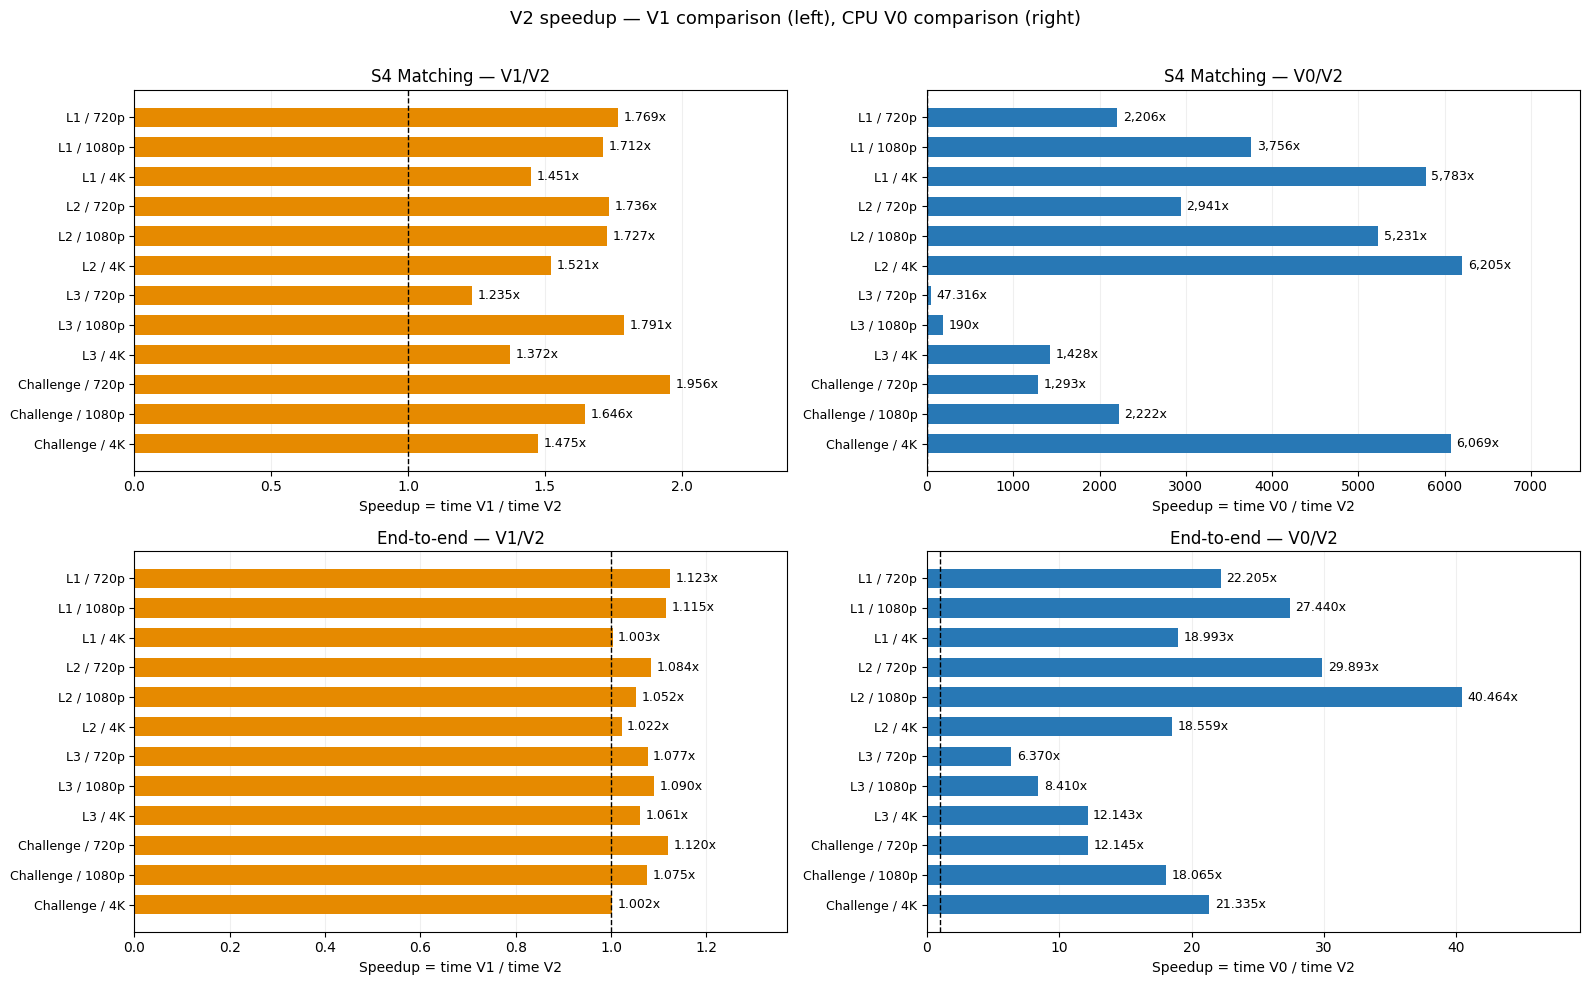

In [10]:
# V2_RESULT_PLOT: one figure, with independent scales for the two comparisons.
if not valid.empty:
    fig,axes = plt.subplots(2,2,figsize=(16,10))
    indexed = valid.set_index('case')
    def case_label(case):
        return (case.replace('location1_','L1 / ').replace('location2_','L2 / ')
                .replace('location3_','L3 / ').replace('challenge_','Challenge / ')
                .replace('small_720p','720p').replace('medium_1080p','1080p')
                .replace('large_4k','4K'))
    for row,(metric,title) in enumerate([('match','S4 Matching'),('end_to_end','End-to-end')]):
        for column,version,color in [(0,1,'#e68a00'),(1,0,'#2878b5')]:
            ax = axes[row,column]
            values = indexed[f'v{version}_over_v2_{metric}_speedup'].dropna()
            positions = list(range(len(values)))
            ax.barh(positions,values.to_numpy(),color=color,height=0.65)
            ax.set_yticks(positions)
            ax.set_yticklabels([case_label(case) for case in values.index],fontsize=9)
            ax.invert_yaxis()
            ax.axvline(1,color='black',linestyle='--',linewidth=1)
            ax.set_xlim(0,max(1.0,float(values.max()) if len(values) else 1.0)*1.22)
            ax.set_title(f'{title} — V{version}/V2')
            ax.set_xlabel(f'Speedup = time V{version} / time V2')
            ax.grid(axis='x',alpha=0.2)
            ax.set_axisbelow(True)
            for position,value in enumerate(values):
                label = f'{value:.3f}x' if version==1 or value<100 else f'{value:,.0f}x'
                ax.annotate(label,(value,position),xytext=(4,0),textcoords='offset points',
                            va='center',fontsize=9)
    fig.suptitle('V2 speedup — V1 comparison (left), CPU V0 comparison (right)',fontsize=13)
    plt.tight_layout(rect=(0,0,1,0.97)); plt.show()
else:
    print('No verified case to plot; inspect correctness/failure logs.')


### 6.3. Panorama đại diện và cặp challenge

Hiển thị panorama V2 ở **1080p** của ba địa điểm và cặp `challenge`. Preview thu nhỏ để notebook gọn; ảnh gốc V0/V1/V2 ở mọi độ phân giải vẫn được lưu trong `RUN_DIR/panoramas/` và dùng cho kiểm chứng.

Trong lần chạy đã lưu, cả bốn cặp ảnh ở 1080p đều tạo được panorama và đạt kiểm chứng, gồm cả `challenge`. Cặp khó này không phải failure case trong lần chạy hiện tại. Khi chạy lại gặp lỗi, cell sẽ hiển thị status và đường dẫn log để kiểm tra.


**location1_medium_1080p — pass**

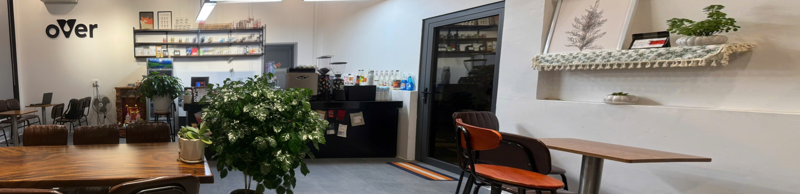

**location2_medium_1080p — pass**

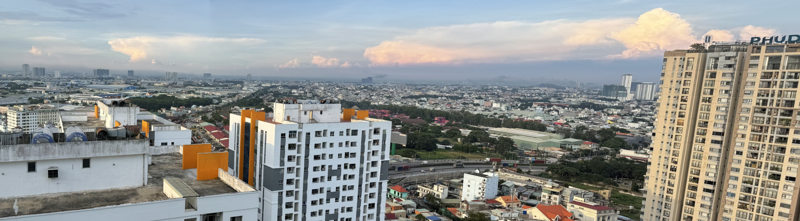

**location3_medium_1080p — pass**

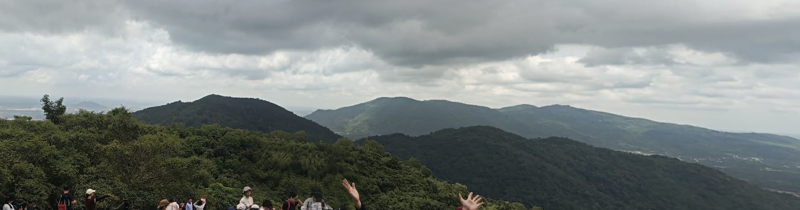

**challenge_medium_1080p — pass**

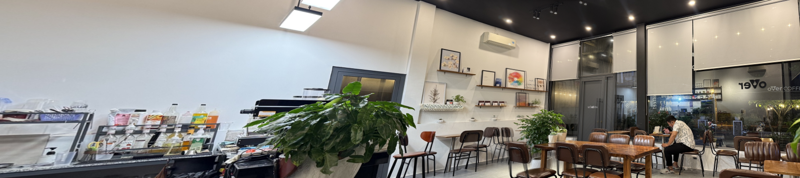

In [11]:
gallery = summary[summary.case.str.endswith('medium_1080p')]
for _,row in gallery.iterrows():
    display(Markdown(f"**{row['case']} — {row['status']}**"))
    report_path = RUN_DIR/f"{row['case']}_v2.json"
    report = json.loads(report_path.read_text(encoding='utf-8')) if report_path.is_file() else {}
    path = Path(report.get('panorama',{}).get('path',''))
    if report.get('status')=='ok' and path.is_file():
        with PILImage.open(path) as original:
            preview = original.copy()
        preview.thumbnail((800,450))
        display(preview)
    else:
        print('No panorama:',report.get('error','missing output'))
    if row['status']!='pass':
        print('Inspect:',RUN_DIR/f"{row['case']}_verification.log")

## 7. Nhận xét

Cả 12 case đều qua kiểm chứng. Matches V0/V1/V2 nhất quán, sai số chiếu homography và sai số pixel trong bảng đều bằng 0. Test S4 và test tích hợp V1/V2 cũng PASS. Cặp `challenge` ghép được panorama nên lần chạy này chưa có ca thất bại để phân tích.

S4 V2 nhanh hơn V1 ở cả 12 case, đạt **1,235–1,956×**. Chẳng hạn, `challenge_small_720p` giảm từ **0,466 ms xuống 0,238 ms**, còn `location3_small_720p` giảm từ **0,112 ms xuống 0,090 ms**. Kết quả cho thấy tiling có lợi cho matching trên bộ ảnh đã thử, nhưng mức cải thiện không tăng đều theo độ phân giải.

Speedup toàn pipeline chỉ đạt **1,002–1,123×**. Điều này phù hợp với tỷ trọng S4 khá nhỏ: khoảng **0,4–2,7% tổng thời gian kernel V1**. S5/S6 và truyền dữ liệu vẫn tốn nhiều thời gian hơn, nên giảm thời gian S4 chỉ cải thiện được một phần nhỏ của pipeline.

Chênh lệch end-to-end cũng không chỉ đến từ S4. Với `location1_small_720p`, S4 giảm khoảng **0,278 ms**, trong khi end-to-end giảm khoảng **7,304 ms**. Cần xem thêm các stage còn lại, copy và dao động giữa các lượt đo để giải thích phần chênh này. Những kết quả gần 1× chưa đủ để khẳng định tăng tốc ổn định.

So với V0, speedup S4 đạt khoảng **47,316–6.204,528×**, còn end-to-end đạt **6,370–40,464×**. Các mức này bao gồm lợi ích chuyển pipeline từ CPU lên GPU đã có ở V1. Để đánh giá riêng tiling của V2, cần nhìn vào V1/V2.

V2 đã giữ được kết quả và giảm thời gian matching trong lần đo này. Tuy vậy, S4 chưa phải phần tốn thời gian nhất của V1. Profiler hiện có cũng chưa đo cache hay memory throughput của cả hai bản, nên chưa thể xác nhận trực tiếp lượng truy cập global memory giảm bao nhiêu. Không có case nào chậm hơn theo thời gian trung bình đã lưu; nếu lần chạy sau có case chậm thì vẫn giữ lại để phân tích.
